<a href="https://colab.research.google.com/github/2303a510c3/Quantum-Computing/blob/main/Product_02_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q "qiskit>=2.5,<3" "qiskit-aer>=0.17,<0.18" matplotlib pandas numpy pytest

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 55.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.7 MB/s eta 0:00:00


In [2]:
import qiskit
import qiskit_aer

print("Qiskit version:", qiskit.__version__)
print("Qiskit Aer version:", qiskit_aer.__version__)
print("Installation successful!")

Qiskit version: 2.5.2
Qiskit Aer version: 0.17.2
Installation successful!


In [3]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import os

OUTPUT_DIR = "quantum_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output folder created:", OUTPUT_DIR)

Output folder created: quantum_outputs


In [5]:
def simulate_circuit(qc, shots=1024):
    """
    Simulate a quantum circuit using Qiskit Aer.
    """

    simulator = AerSimulator()

    compiled_circuit = transpile(
        qc,
        simulator
    )

    result = simulator.run(
        compiled_circuit,
        shots=shots
    ).result()

    counts = result.get_counts()

    return counts

In [6]:
def plot_counts(counts, title):
    """
    Plot measurement counts.
    """

    states = list(counts.keys())
    values = list(counts.values())

    plt.figure(figsize=(10, 5))

    plt.bar(states, values)

    plt.title(title)
    plt.xlabel("Measurement State")
    plt.ylabel("Number of Shots")

    plt.xticks(rotation=60)

    plt.tight_layout()

    plt.show()

In [7]:
def deutsch_jozsa_circuit(n=3, oracle_type="balanced"):
    """
    Deutsch-Jozsa quantum circuit.

    n = number of input qubits
    oracle_type = balanced or constant
    """

    if n < 1:
        raise ValueError("n must be at least 1")

    if oracle_type not in ["balanced", "constant"]:
        raise ValueError(
            "oracle_type must be 'balanced' or 'constant'"
        )

    qc = QuantumCircuit(n + 1, n)

    # Last qubit is the ancilla
    ancilla = n

    # Prepare ancilla in |1>
    qc.x(ancilla)

    # Apply Hadamard to all qubits
    qc.h(range(n + 1))

    qc.barrier()

    # Balanced oracle
    if oracle_type == "balanced":

        for qubit in range(n):
            qc.cx(qubit, ancilla)

    qc.barrier()

    # Hadamard on input qubits
    qc.h(range(n))

    # Measure input qubits
    qc.measure(range(n), range(n))

    return qc

In [8]:
!pip install -q pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.3 MB/s eta 0:00:00


In [9]:
dj_circuit = deutsch_jozsa_circuit(
    n=3,
    oracle_type="balanced"
)

print("Deutsch-Jozsa Circuit:")
print(dj_circuit.draw(output="text"))

Deutsch-Jozsa Circuit:
     ┌───┐      ░                 ░ ┌───┐┌─┐      
q_0: ┤ H ├──────░───■─────────────░─┤ H ├┤M├──────
     ├───┤      ░   │             ░ ├───┤└╥┘┌─┐   
q_1: ┤ H ├──────░───┼────■────────░─┤ H ├─╫─┤M├───
     ├───┤      ░   │    │        ░ ├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├──────░───┼────┼────■───░─┤ H ├─╫──╫─┤M├
     ├───┤┌───┐ ░ ┌─┴─┐┌─┴─┐┌─┴─┐ ░ └───┘ ║  ║ └╥┘
q_3: ┤ X ├┤ H ├─░─┤ X ├┤ X ├┤ X ├─░───────╫──╫──╫─
     └───┘└───┘ ░ └───┘└───┘└───┘ ░       ║  ║  ║ 
c: 3/═════════════════════════════════════╩══╩══╩═
                                          0  1  2 


Deutsch-Jozsa Results:
{'111': 1024}


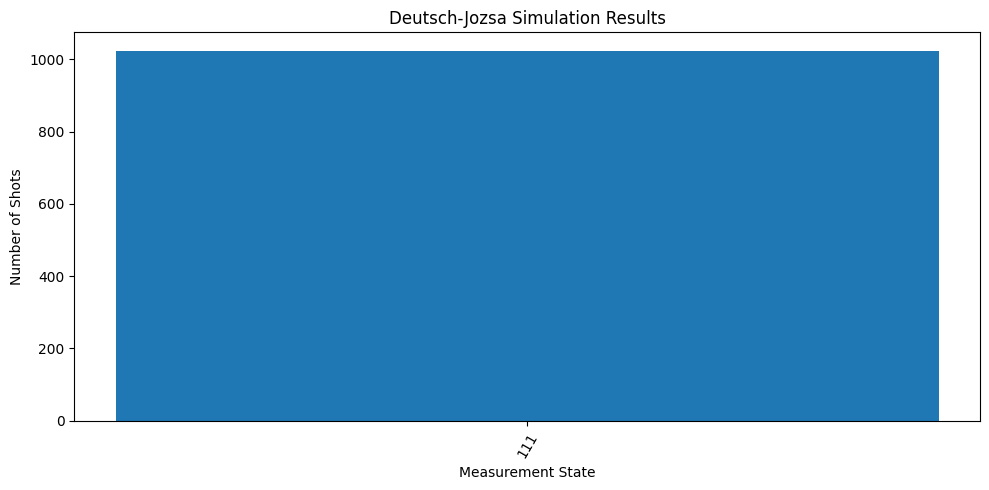

In [10]:
dj_counts = simulate_circuit(
    dj_circuit,
    shots=1024
)

print("Deutsch-Jozsa Results:")
print(dj_counts)

plot_counts(
    dj_counts,
    "Deutsch-Jozsa Simulation Results"
)

In [11]:
def bernstein_vazirani_circuit(secret="1011"):
    """
    Bernstein-Vazirani circuit.

    secret = hidden binary string
    """

    if not secret:
        raise ValueError("Secret cannot be empty")

    if any(bit not in "01" for bit in secret):
        raise ValueError(
            "Secret must contain only 0 and 1"
        )

    n = len(secret)

    qc = QuantumCircuit(n + 1, n)

    ancilla = n

    # Ancilla |1>
    qc.x(ancilla)

    # Superposition
    qc.h(range(n + 1))

    qc.barrier()

    # Oracle
    for i, bit in enumerate(reversed(secret)):

        if bit == "1":
            qc.cx(i, ancilla)

    qc.barrier()

    # Decode
    qc.h(range(n))

    # Measurement
    qc.measure(range(n), range(n))

    return qc

In [12]:
!pip install -q pylatexenc

Bernstein-Vazirani Circuit:

     ┌───┐      ░                 ░ ┌───┐┌─┐         
q_0: ┤ H ├──────░───■─────────────░─┤ H ├┤M├─────────
     ├───┤      ░   │             ░ ├───┤└╥┘┌─┐      
q_1: ┤ H ├──────░───┼────■────────░─┤ H ├─╫─┤M├──────
     ├───┤      ░   │    │        ░ ├───┤ ║ └╥┘┌─┐   
q_2: ┤ H ├──────░───┼────┼────────░─┤ H ├─╫──╫─┤M├───
     ├───┤      ░   │    │        ░ ├───┤ ║  ║ └╥┘┌─┐
q_3: ┤ H ├──────░───┼────┼────■───░─┤ H ├─╫──╫──╫─┤M├
     ├───┤┌───┐ ░ ┌─┴─┐┌─┴─┐┌─┴─┐ ░ └───┘ ║  ║  ║ └╥┘
q_4: ┤ X ├┤ H ├─░─┤ X ├┤ X ├┤ X ├─░───────╫──╫──╫──╫─
     └───┘└───┘ ░ └───┘└───┘└───┘ ░       ║  ║  ║  ║ 
c: 4/═════════════════════════════════════╩══╩══╩══╩═
                                          0  1  2  3 

Bernstein-Vazirani Results:
{'1011': 1024}


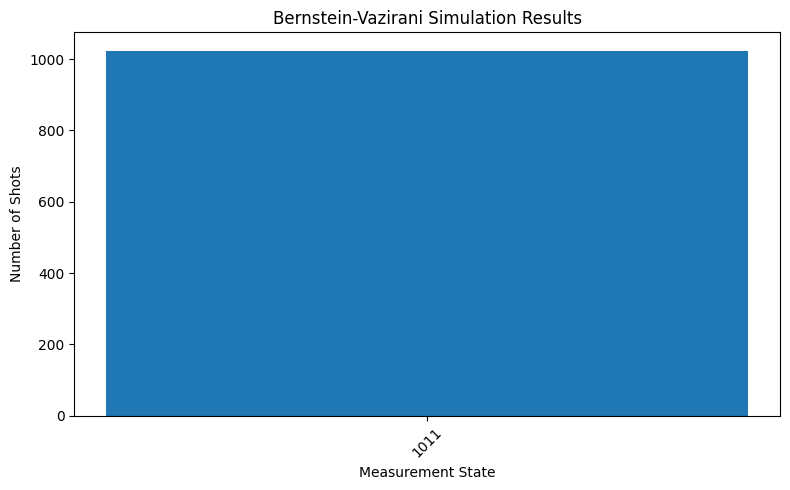


Expected secret: 1011
Measured secret: 1011


In [13]:
# ============================================================
# Bernstein-Vazirani Algorithm - Complete Colab Cell
# ============================================================

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from IPython.display import display
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Bernstein-Vazirani Circuit
# ------------------------------------------------------------

def bernstein_vazirani_circuit(secret="1011"):

    if not secret:
        raise ValueError("Secret cannot be empty.")

    if any(bit not in "01" for bit in secret):
        raise ValueError("Secret must contain only 0 and 1.")

    n = len(secret)

    # n input qubits + 1 ancilla
    qc = QuantumCircuit(n + 1, n)

    ancilla = n

    # Prepare ancilla in |1>
    qc.x(ancilla)

    # Hadamard on all qubits
    qc.h(range(n + 1))

    qc.barrier()

    # Oracle
    for i, bit in enumerate(reversed(secret)):
        if bit == "1":
            qc.cx(i, ancilla)

    qc.barrier()

    # Hadamard on input qubits
    qc.h(range(n))

    # Measure input qubits
    qc.measure(range(n), range(n))

    return qc


# ------------------------------------------------------------
# 2. Simulation Function
# ------------------------------------------------------------

def simulate_circuit(qc, shots=1024):

    simulator = AerSimulator()

    compiled_circuit = transpile(
        qc,
        simulator
    )

    result = simulator.run(
        compiled_circuit,
        shots=shots
    ).result()

    return result.get_counts()


# ------------------------------------------------------------
# 3. Plot Function
# ------------------------------------------------------------

def plot_counts(counts, title):

    states = list(counts.keys())
    values = list(counts.values())

    plt.figure(figsize=(8, 5))

    plt.bar(states, values)

    plt.title(title)
    plt.xlabel("Measurement State")
    plt.ylabel("Number of Shots")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 4. Run Bernstein-Vazirani
# ------------------------------------------------------------

secret = "1011"

bv_circuit = bernstein_vazirani_circuit(secret)

print("Bernstein-Vazirani Circuit:")
print()

# Use text drawer - works reliably in Colab
print(bv_circuit.draw(output="text"))


# ------------------------------------------------------------
# 5. Simulation
# ------------------------------------------------------------

bv_counts = simulate_circuit(
    bv_circuit,
    shots=1024
)

print("\nBernstein-Vazirani Results:")
print(bv_counts)


# ------------------------------------------------------------
# 6. Plot Results
# ------------------------------------------------------------

plot_counts(
    bv_counts,
    "Bernstein-Vazirani Simulation Results"
)


# ------------------------------------------------------------
# 7. Most Likely Result
# ------------------------------------------------------------

most_likely = max(
    bv_counts,
    key=bv_counts.get
)

print("\nExpected secret:", secret)
print("Measured secret:", most_likely)

In [14]:
def simon_oracle(secret):
    """
    Construct a simple linear Simon oracle.

    The oracle is designed so that:
        f(x) = f(x XOR s)
    """

    n = len(secret)

    if n < 2:
        raise ValueError(
            "Simon secret must have at least 2 bits"
        )

    if any(bit not in "01" for bit in secret):
        raise ValueError(
            "Secret must contain only 0 and 1"
        )

    if set(secret) == {"0"}:
        raise ValueError(
            "Simon secret cannot be all zero"
        )

    qc = QuantumCircuit(2 * n)

    s = [int(bit) for bit in reversed(secret)]

    # Find pivot
    pivot = s.index(1)

    # Copy input bits to output
    for i in range(n):

        if i != pivot:

            qc.cx(
                i,
                n + i
            )

    # Modify pivot output
    for i in range(n):

        if i != pivot and s[i] == 1:

            qc.cx(
                i,
                n + pivot
            )

    return qc

In [15]:
def simon_circuit(secret="110"):

    n = len(secret)

    qc = QuantumCircuit(
        2 * n,
        n
    )

    # Initial superposition
    qc.h(range(n))

    qc.barrier()

    # Simon oracle
    oracle = simon_oracle(secret)

    qc.compose(
        oracle,
        qubits=range(2 * n),
        inplace=True
    )

    qc.barrier()

    # Interference
    qc.h(range(n))

    # Measurement
    qc.measure(
        range(n),
        range(n)
    )

    return qc

In [ ]:
!pip install -q pylatexenc

SIMON'S ALGORITHM

Secret: 110

Simon's Algorithm Circuit:

     ┌───┐ ░                 ░ ┌───┐ ░ ┌─┐      
q_0: ┤ H ├─░───■─────────────░─┤ H ├─░─┤M├──────
     ├───┤ ░   │             ░ ├───┤ ░ └╥┘┌─┐   
q_1: ┤ H ├─░───┼─────────────░─┤ H ├─░──╫─┤M├───
     ├───┤ ░   │             ░ ├───┤ ░  ║ └╥┘┌─┐
q_2: ┤ H ├─░───┼────■────■───░─┤ H ├─░──╫──╫─┤M├
     └───┘ ░ ┌─┴─┐  │    │   ░ └───┘ ░  ║  ║ └╥┘
q_3: ──────░─┤ X ├──┼────┼───░───────░──╫──╫──╫─
           ░ └───┘  │  ┌─┴─┐ ░       ░  ║  ║  ║ 
q_4: ──────░────────┼──┤ X ├─░───────░──╫──╫──╫─
           ░      ┌─┴─┐└───┘ ░       ░  ║  ║  ║ 
q_5: ──────░──────┤ X ├──────░───────░──╫──╫──╫─
           ░      └───┘      ░       ░  ║  ║  ║ 
c: 3/═══════════════════════════════════╩══╩══╩═
                                        0  1  2 

Simon's Algorithm Results:
{'101': 545, '100': 482, '001': 524, '000': 497}


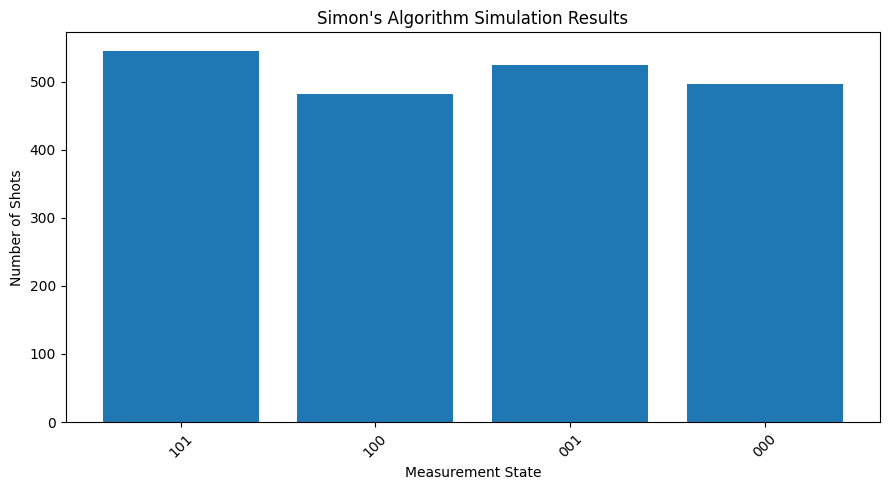


Most frequently measured state: 101

Simon condition:
y · s = 0  (mod 2)

Secret string:
110

Simulation completed successfully!


In [16]:
# ============================================================
# SIMON'S ALGORITHM - COMPLETE GOOGLE COLAB CODE
# ============================================================

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
from IPython.display import display


# ============================================================
# 1. Simon Oracle
# ============================================================

def simon_oracle(secret):
    """
    Create a Simon oracle satisfying:

        f(x) = f(x XOR s)

    secret = hidden Simon string
    """

    n = len(secret)

    # Validate secret
    if n < 2:
        raise ValueError(
            "Secret must contain at least 2 bits."
        )

    if any(bit not in "01" for bit in secret):
        raise ValueError(
            "Secret must contain only 0 and 1."
        )

    if set(secret) == {"0"}:
        raise ValueError(
            "Secret cannot be all zeros."
        )

    qc = QuantumCircuit(2 * n)

    # Convert secret into integer bits
    s = [int(bit) for bit in reversed(secret)]

    # Find position of first 1
    pivot = s.index(1)

    # --------------------------------------------------------
    # Oracle construction
    # --------------------------------------------------------

    for i in range(n):

        if i != pivot:

            qc.cx(
                i,
                n + i
            )

    # Add dependence on the secret
    for i in range(n):

        if i != pivot and s[i] == 1:

            qc.cx(
                i,
                n + pivot
            )

    return qc


# ============================================================
# 2. Simon Circuit
# ============================================================

def simon_circuit(secret="110"):

    n = len(secret)

    qc = QuantumCircuit(
        2 * n,
        n
    )

    # --------------------------------------------------------
    # Step 1: Put first register into superposition
    # --------------------------------------------------------

    qc.h(range(n))

    qc.barrier()

    # --------------------------------------------------------
    # Step 2: Apply Simon oracle
    # --------------------------------------------------------

    oracle = simon_oracle(secret)

    qc.compose(
        oracle,
        qubits=range(2 * n),
        inplace=True
    )

    qc.barrier()

    # --------------------------------------------------------
    # Step 3: Apply Hadamard again
    # --------------------------------------------------------

    qc.h(range(n))

    qc.barrier()

    # --------------------------------------------------------
    # Step 4: Measure first register
    # --------------------------------------------------------

    qc.measure(
        range(n),
        range(n)
    )

    return qc


# ============================================================
# 3. Simulation Function
# ============================================================

def simulate_circuit(qc, shots=2048):

    simulator = AerSimulator()

    compiled = transpile(
        qc,
        simulator
    )

    result = simulator.run(
        compiled,
        shots=shots
    ).result()

    counts = result.get_counts()

    return counts


# ============================================================
# 4. Plot Function
# ============================================================

def plot_counts(counts, title):

    states = list(counts.keys())
    values = list(counts.values())

    plt.figure(figsize=(9, 5))

    plt.bar(
        states,
        values
    )

    plt.title(title)
    plt.xlabel("Measurement State")
    plt.ylabel("Number of Shots")

    plt.xticks(
        rotation=45
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 5. Run Simon's Algorithm
# ============================================================

simon_secret = "110"

simon_qc = simon_circuit(
    simon_secret
)

print("=" * 60)
print("SIMON'S ALGORITHM")
print("=" * 60)

print("\nSecret:", simon_secret)

print("\nSimon's Algorithm Circuit:")
print()

# Text circuit is more reliable in Colab
print(
    simon_qc.draw(
        output="text"
    )
)


# ============================================================
# 6. Run Simulation
# ============================================================

simon_counts = simulate_circuit(
    simon_qc,
    shots=2048
)

print("\nSimon's Algorithm Results:")
print(simon_counts)


# ============================================================
# 7. Plot Results
# ============================================================

plot_counts(
    simon_counts,
    "Simon's Algorithm Simulation Results"
)


# ============================================================
# 8. Most Frequent Result
# ============================================================

most_likely = max(
    simon_counts,
    key=simon_counts.get
)

print(
    "\nMost frequently measured state:",
    most_likely
)


# ============================================================
# 9. Simon Mathematical Condition
# ============================================================

print("\nSimon condition:")
print("y · s = 0  (mod 2)")

print("\nSecret string:")
print(simon_secret)

print("\nSimulation completed successfully!")

In [17]:
def grover_circuit(
    n=3,
    marked="101"
):
    """
    Grover search for a single marked state.
    """

    if len(marked) != n:
        raise ValueError(
            "Marked state length must equal n"
        )

    if any(bit not in "01" for bit in marked):
        raise ValueError(
            "Marked state must contain only 0 and 1"
        )

    qc = QuantumCircuit(
        n,
        n
    )

    # --------------------------------
    # Initial superposition
    # --------------------------------

    qc.h(range(n))

    qc.barrier()

    # --------------------------------
    # Oracle
    # --------------------------------

    for i, bit in enumerate(
        reversed(marked)
    ):

        if bit == "0":
            qc.x(i)

    qc.h(n - 1)

    qc.mcx(
        list(range(n - 1)),
        n - 1
    )

    qc.h(n - 1)

    for i, bit in enumerate(
        reversed(marked)
    ):

        if bit == "0":
            qc.x(i)

    qc.barrier()

    # --------------------------------
    # Diffusion operator
    # --------------------------------

    qc.h(range(n))

    qc.x(range(n))

    qc.h(n - 1)

    qc.mcx(
        list(range(n - 1)),
        n - 1
    )

    qc.h(n - 1)

    qc.x(range(n))

    qc.h(range(n))

    qc.barrier()

    # Measurement
    qc.measure(
        range(n),
        range(n)
    )

    return qc

In [18]:
!pip install -q pylatexenc

GROVER'S SEARCH ALGORITHM

Number of qubits: 3
Marked state: 101

Grover Search Circuit:

     ┌───┐ ░                 ░ ┌───┐┌───┐          ┌───┐┌───┐      ░ ┌─┐      
q_0: ┤ H ├─░────────■────────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░─┤M├──────
     ├───┤ ░ ┌───┐  │  ┌───┐ ░ ├───┤├───┤       │  ├───┤├───┤      ░ └╥┘┌─┐   
q_1: ┤ H ├─░─┤ X ├──■──┤ X ├─░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░──╫─┤M├───
     ├───┤ ░ ├───┤┌─┴─┐├───┤ ░ ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐ ░  ║ └╥┘┌─┐
q_2: ┤ H ├─░─┤ H ├┤ X ├┤ H ├─░─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─░──╫──╫─┤M├
     └───┘ ░ └───┘└───┘└───┘ ░ └───┘└───┘└───┘└───┘└───┘└───┘└───┘ ░  ║  ║ └╥┘
c: 3/═════════════════════════════════════════════════════════════════╩══╩══╩═
                                                                      0  1  2 

Grover Results:
{'010': 69, '000': 59, '001': 53, '100': 67, '110': 59, '111': 63, '011': 56, '101': 1622}


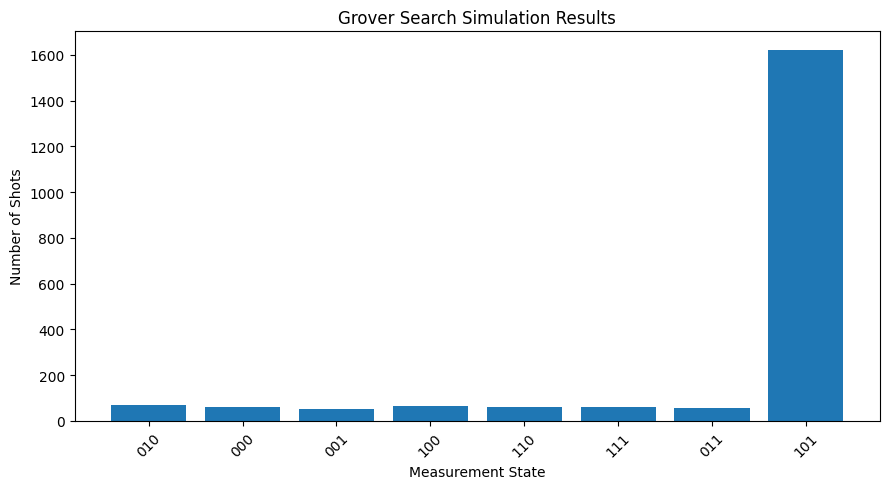


Expected marked state: 101
Most likely measured state: 101

Grover simulation completed successfully!


In [19]:
# ============================================================
# GROVER'S SEARCH ALGORITHM - GOOGLE COLAB
# ============================================================

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from IPython.display import display
import matplotlib.pyplot as plt


# ============================================================
# 1. Simulation Function
# ============================================================

def simulate_circuit(qc, shots=2048):

    simulator = AerSimulator()

    # Transpile circuit for simulator
    compiled_circuit = transpile(
        qc,
        simulator
    )

    # Run simulation
    result = simulator.run(
        compiled_circuit,
        shots=shots
    ).result()

    return result.get_counts()


# ============================================================
# 2. Plot Function
# ============================================================

def plot_counts(counts, title):

    states = list(counts.keys())
    values = list(counts.values())

    plt.figure(figsize=(9, 5))

    plt.bar(
        states,
        values
    )

    plt.title(title)
    plt.xlabel("Measurement State")
    plt.ylabel("Number of Shots")

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()


# ============================================================
# 3. Grover Circuit
# ============================================================

def grover_circuit(n=3, marked="101"):

    # Check input
    if len(marked) != n:
        raise ValueError(
            "Length of marked state must equal n."
        )

    if any(bit not in "01" for bit in marked):
        raise ValueError(
            "Marked state must contain only 0 and 1."
        )

    qc = QuantumCircuit(n, n)

    # --------------------------------------------------------
    # Step 1: Create equal superposition
    # --------------------------------------------------------

    qc.h(range(n))

    qc.barrier()

    # --------------------------------------------------------
    # Step 2: Oracle
    # --------------------------------------------------------

    # Convert marked state so it matches Qiskit's
    # little-endian qubit ordering
    reversed_marked = marked[::-1]

    # Flip zero bits
    for i, bit in enumerate(reversed_marked):

        if bit == "0":
            qc.x(i)

    # Multi-controlled phase flip
    qc.h(n - 1)

    qc.mcx(
        list(range(n - 1)),
        n - 1
    )

    qc.h(n - 1)

    # Undo X gates
    for i, bit in enumerate(reversed_marked):

        if bit == "0":
            qc.x(i)

    qc.barrier()

    # --------------------------------------------------------
    # Step 3: Diffusion operator
    # --------------------------------------------------------

    qc.h(range(n))

    qc.x(range(n))

    qc.h(n - 1)

    qc.mcx(
        list(range(n - 1)),
        n - 1
    )

    qc.h(n - 1)

    qc.x(range(n))

    qc.h(range(n))

    qc.barrier()

    # --------------------------------------------------------
    # Step 4: Measurement
    # --------------------------------------------------------

    qc.measure(
        range(n),
        range(n)
    )

    return qc


# ============================================================
# 4. Run Grover's Search
# ============================================================

n = 3

marked_state = "101"

grover_qc = grover_circuit(
    n,
    marked_state
)

print("=" * 60)
print("GROVER'S SEARCH ALGORITHM")
print("=" * 60)

print("\nNumber of qubits:", n)
print("Marked state:", marked_state)

print("\nGrover Search Circuit:")
print()

# Use text drawing first - reliable in Colab
print(
    grover_qc.draw(
        output="text"
    )
)


# ============================================================
# 5. Simulation
# ============================================================

grover_counts = simulate_circuit(
    grover_qc,
    shots=2048
)

print("\nGrover Results:")
print(grover_counts)


# ============================================================
# 6. Plot Results
# ============================================================

plot_counts(
    grover_counts,
    "Grover Search Simulation Results"
)


# ============================================================
# 7. Find Most Likely State
# ============================================================

most_likely = max(
    grover_counts,
    key=grover_counts.get
)

print(
    "\nExpected marked state:",
    marked_state
)

print(
    "Most likely measured state:",
    most_likely
)

print("\nGrover simulation completed successfully!")

In [20]:
def create_qft_circuit(n=3):
    """
    Create an n-qubit Quantum Fourier Transform circuit.
    """

    qc = QuantumCircuit(
        n,
        n
    )

    # Prepare |1>
    qc.x(0)

    # QFT
    for j in range(n):

        qc.h(j)

        for k in range(
            j + 1,
            n
        ):

            angle = np.pi / (
                2 ** (k - j)
            )

            qc.cp(
                angle,
                k,
                j
            )

    # Swap qubits
    for i in range(
        n // 2
    ):

        qc.swap(
            i,
            n - i - 1
        )

    qc.barrier()

    qc.measure(
        range(n),
        range(n)
    )

    return qc

In [21]:
!pip install -q pylatexenc

QUANTUM FOURIER TRANSFORM

QFT Circuit:

     ┌───┐ ░ ┌───┐                                         ░ ┌─┐      
q_0: ┤ X ├─░─┤ H ├─■────────■───────────────────────────X──░─┤M├──────
     └───┘ ░ └───┘ │P(π/2)  │       ┌───┐               │  ░ └╥┘┌─┐   
q_1: ──────░───────■────────┼───────┤ H ├─■─────────────┼──░──╫─┤M├───
           ░                │P(π/4) └───┘ │P(π/2) ┌───┐ │  ░  ║ └╥┘┌─┐
q_2: ──────░────────────────■─────────────■───────┤ H ├─X──░──╫──╫─┤M├
           ░                                      └───┘    ░  ║  ║ └╥┘
c: 3/═════════════════════════════════════════════════════════╩══╩══╩═
                                                              0  1  2 

QFT Results:
{'001': 277, '101': 242, '100': 248, '000': 266, '010': 273, '110': 246, '011': 250, '111': 246}


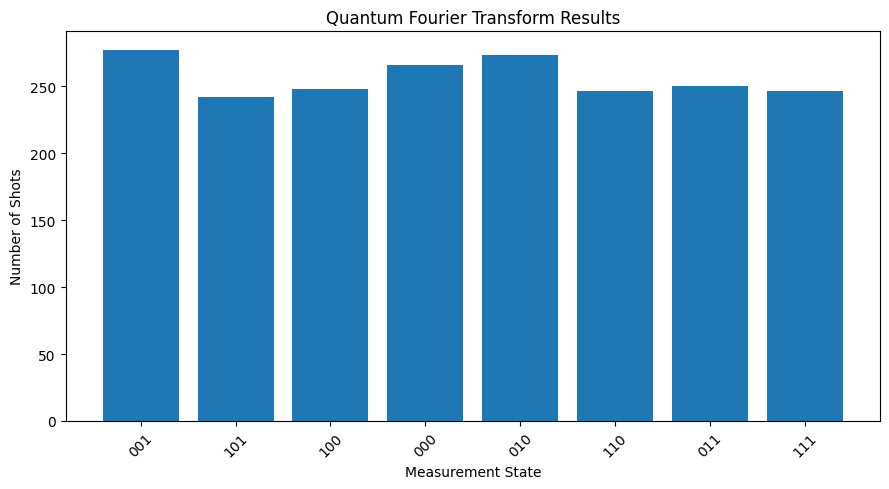


Most likely measured state: 001

QFT simulation completed successfully!


In [22]:
# ============================================================
# QUANTUM FOURIER TRANSFORM (QFT)
# Complete Google Colab Code
# ============================================================

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display


# ============================================================
# 1. Create QFT Circuit
# ============================================================

def create_qft_circuit(n=3):

    if n < 1:
        raise ValueError("Number of qubits must be at least 1.")

    qc = QuantumCircuit(n, n)

    # --------------------------------------------------------
    # Prepare input state |1>
    # --------------------------------------------------------

    qc.x(0)

    qc.barrier()

    # --------------------------------------------------------
    # QFT
    # --------------------------------------------------------

    for j in range(n):

        # Hadamard
        qc.h(j)

        # Controlled phase rotations
        for k in range(j + 1, n):

            angle = np.pi / (2 ** (k - j))

            qc.cp(
                angle,
                k,
                j
            )

    # --------------------------------------------------------
    # Reverse qubit order using SWAP gates
    # --------------------------------------------------------

    for i in range(n // 2):

        qc.swap(
            i,
            n - i - 1
        )

    qc.barrier()

    # --------------------------------------------------------
    # Measurement
    # --------------------------------------------------------

    qc.measure(
        range(n),
        range(n)
    )

    return qc


# ============================================================
# 2. Simulation Function
# ============================================================

def simulate_circuit(qc, shots=2048):

    simulator = AerSimulator()

    compiled_circuit = transpile(
        qc,
        simulator
    )

    result = simulator.run(
        compiled_circuit,
        shots=shots
    ).result()

    counts = result.get_counts()

    return counts


# ============================================================
# 3. Plot Function
# ============================================================

def plot_counts(counts, title):

    states = list(counts.keys())
    values = list(counts.values())

    plt.figure(figsize=(9, 5))

    plt.bar(
        states,
        values
    )

    plt.title(title)
    plt.xlabel("Measurement State")
    plt.ylabel("Number of Shots")

    plt.xticks(
        rotation=45
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 4. Create QFT Circuit
# ============================================================

qft_qc = create_qft_circuit(
    n=3
)


# ============================================================
# 5. Display Circuit
# ============================================================

print("=" * 60)
print("QUANTUM FOURIER TRANSFORM")
print("=" * 60)

print("\nQFT Circuit:\n")

# Text output is reliable in Google Colab
print(
    qft_qc.draw(
        output="text"
    )
)


# ============================================================
# 6. Run Simulation
# ============================================================

qft_counts = simulate_circuit(
    qft_qc,
    shots=2048
)

print("\nQFT Results:")
print(qft_counts)


# ============================================================
# 7. Plot Results
# ============================================================

plot_counts(
    qft_counts,
    "Quantum Fourier Transform Results"
)


# ============================================================
# 8. Most Likely Result
# ============================================================

most_likely = max(
    qft_counts,
    key=qft_counts.get
)

print(
    "\nMost likely measured state:",
    most_likely
)

print("\nQFT simulation completed successfully!")

In [23]:
complexity_data = {

    "Algorithm": [
        "Deutsch-Jozsa",
        "Bernstein-Vazirani",
        "Simon's Algorithm",
        "Grover's Search",
        "QFT"
    ],

    "Quantum Complexity": [
        "1 oracle query",
        "1 oracle query",
        "O(n) samples",
        "O(2^(n/2))",
        "O(n^2)"
    ],

    "Classical Complexity": [
        "O(2^n) worst case",
        "O(n)",
        "O(2^(n/2)) or exponential depending on model",
        "O(2^n)",
        "O(n*2^n)"
    ],

    "Quantum Advantage": [
        "Exponential query reduction",
        "Linear query reduction",
        "Exponential separation",
        "Quadratic speedup",
        "Efficient transform on quantum amplitudes"
    ]
}

complexity_df = pd.DataFrame(
    complexity_data
)

display(complexity_df)

,Algorithm,Quantum Complexity,Classical Complexity,Quantum Advantage
0,Deutsch-Jozsa,1 oracle query,O(2^n) worst case,Exponential query reduction
1,Bernstein-Vazirani,1 oracle query,O(n),Linear query reduction
2,Simon's Algorithm,O(n) samples,O(2^(n/2)) or exponential depending on model,Exponential separation
3,Grover's Search,O(2^(n/2)),O(2^n),Quadratic speedup
4,QFT,O(n^2),O(n*2^n),Efficient transform on quantum amplitudes


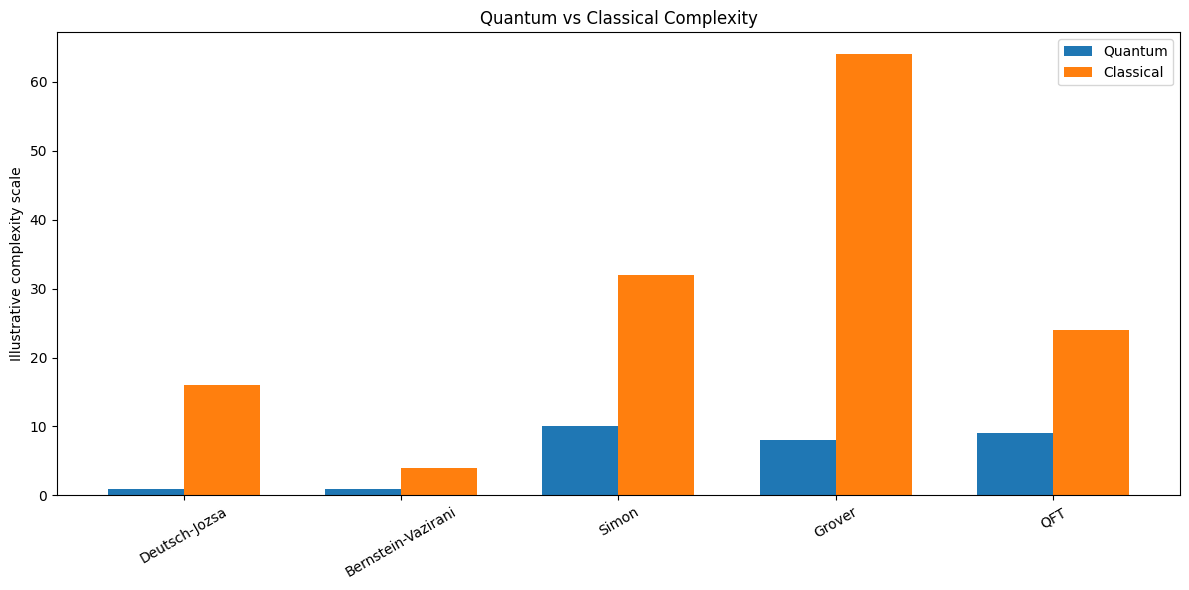

In [24]:
algorithms = [
    "Deutsch-Jozsa",
    "Bernstein-Vazirani",
    "Simon",
    "Grover",
    "QFT"
]

quantum_values = [
    1,
    1,
    10,
    8,
    9
]

classical_values = [
    16,
    4,
    32,
    64,
    24
]

x = np.arange(
    len(algorithms)
)

width = 0.35

plt.figure(
    figsize=(12, 6)
)

plt.bar(
    x - width/2,
    quantum_values,
    width,
    label="Quantum"
)

plt.bar(
    x + width/2,
    classical_values,
    width,
    label="Classical"
)

plt.xticks(
    x,
    algorithms,
    rotation=30
)

plt.ylabel(
    "Illustrative complexity scale"
)

plt.title(
    "Quantum vs Classical Complexity"
)

plt.legend()

plt.tight_layout()

plt.show()

In [25]:
def transpilation_analysis(qc):

    simulator = AerSimulator()

    results = []

    for level in range(4):

        transpiled_qc = transpile(
            qc,
            simulator,
            optimization_level=level
        )

        results.append({

            "Optimization Level":
                level,

            "Depth":
                transpiled_qc.depth(),

            "Gate Count":
                transpiled_qc.size(),

            "Qubits":
                transpiled_qc.num_qubits,

            "Non-local Gates":
                transpiled_qc.num_nonlocal_gates()
        })

    return pd.DataFrame(
        results
    )

In [26]:
dj_transpilation = transpilation_analysis(
    dj_circuit
)

display(
    dj_transpilation
)

,Optimization Level,Depth,Gate Count,Qubits,Non-local Gates
0,0,7,14,4,3
1,1,6,13,4,3
2,2,6,13,4,3
3,3,6,13,4,3


In [27]:
bv_transpilation = transpilation_analysis(
    bv_circuit
)

display(
    bv_transpilation
)

,Optimization Level,Depth,Gate Count,Qubits,Non-local Gates
0,0,7,17,5,3
1,1,6,16,5,3
2,2,6,16,5,3
3,3,6,16,5,3


In [28]:
simon_transpilation = transpilation_analysis(
    simon_qc
)

display(
    simon_transpilation
)

,Optimization Level,Depth,Gate Count,Qubits,Non-local Gates
0,0,5,12,6,3
1,1,5,12,6,3
2,2,5,12,6,3
3,3,5,12,6,3


In [29]:
grover_transpilation = transpilation_analysis(
    grover_qc
)

display(
    grover_transpilation
)

,Optimization Level,Depth,Gate Count,Qubits,Non-local Gates
0,0,12,26,3,2
1,1,8,18,3,2
2,2,8,18,3,2
3,3,8,18,3,2


In [30]:
qft_transpilation = transpilation_analysis(
    qft_qc
)

display(
    qft_transpilation
)

,Optimization Level,Depth,Gate Count,Qubits,Non-local Gates
0,0,8,11,3,4
1,1,8,11,3,4
2,2,7,10,3,3
3,3,7,10,3,3


In [31]:
from qiskit.visualization import plot_histogram

# Save histogram images

plot_histogram(
    dj_counts,
    filename=f"{OUTPUT_DIR}/deutsch_jozsa_histogram.png"
)

plot_histogram(
    bv_counts,
    filename=f"{OUTPUT_DIR}/bernstein_vazirani_histogram.png"
)

plot_histogram(
    simon_counts,
    filename=f"{OUTPUT_DIR}/simon_histogram.png"
)

plot_histogram(
    grover_counts,
    filename=f"{OUTPUT_DIR}/grover_histogram.png"
)

plot_histogram(
    qft_counts,
    filename=f"{OUTPUT_DIR}/qft_histogram.png"
)

print(
    "Result plots saved in:",
    OUTPUT_DIR
)

Result plots saved in: quantum_outputs


In [32]:
!pip install -q pylatexenc

In [33]:
# ============================================================
# SAVE ALL QUANTUM CIRCUIT DIAGRAMS
# Google Colab - ERROR FREE VERSION
# ============================================================

import os
import matplotlib.pyplot as plt


# ============================================================
# 1. Create output folder
# ============================================================

OUTPUT_DIR = "quantum_outputs"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

print("Saving circuit diagrams...")
print()


# ============================================================
# 2. Function to save circuit as PNG
# ============================================================

def save_circuit_as_png(circuit, filename, title):
    """
    Save a Qiskit circuit as a PNG image.

    Uses Qiskit's text drawer, so pylatexenc
    is NOT required.
    """

    # Convert circuit to text
    circuit_text = circuit.draw(
        output="text"
    )

    # Create figure
    fig = plt.figure(
        figsize=(16, 8)
    )

    # Remove axes
    plt.axis("off")

    # Add title
    plt.title(
        title,
        fontsize=18,
        pad=20
    )

    # Display circuit text
    plt.text(
        0.01,
        0.95,
        str(circuit_text),
        fontsize=10,
        fontfamily="monospace",
        verticalalignment="top",
        transform=plt.gca().transAxes
    )

    # Save image
    plt.savefig(
        filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.close(fig)


# ============================================================
# 3. Deutsch-Jozsa
# ============================================================

save_circuit_as_png(
    dj_circuit,
    os.path.join(
        OUTPUT_DIR,
        "deutsch_jozsa_circuit.png"
    ),
    "Deutsch-Jozsa Algorithm Circuit"
)

print(
    "✓ Deutsch-Jozsa circuit saved"
)


# ============================================================
# 4. Bernstein-Vazirani
# ============================================================

save_circuit_as_png(
    bv_circuit,
    os.path.join(
        OUTPUT_DIR,
        "bernstein_vazirani_circuit.png"
    ),
    "Bernstein-Vazirani Algorithm Circuit"
)

print(
    "✓ Bernstein-Vazirani circuit saved"
)


# ============================================================
# 5. Simon's Algorithm
# ============================================================

save_circuit_as_png(
    simon_qc,
    os.path.join(
        OUTPUT_DIR,
        "simon_circuit.png"
    ),
    "Simon's Algorithm Circuit"
)

print(
    "✓ Simon's Algorithm circuit saved"
)


# ============================================================
# 6. Grover's Search
# ============================================================

save_circuit_as_png(
    grover_qc,
    os.path.join(
        OUTPUT_DIR,
        "grover_circuit.png"
    ),
    "Grover's Search Algorithm Circuit"
)

print(
    "✓ Grover circuit saved"
)


# ============================================================
# 7. QFT
# ============================================================

save_circuit_as_png(
    qft_qc,
    os.path.join(
        OUTPUT_DIR,
        "qft_circuit.png"
    ),
    "Quantum Fourier Transform Circuit"
)

print(
    "✓ QFT circuit saved"
)


# ============================================================
# 8. Final Verification
# ============================================================

print()
print("=" * 60)
print("ALL CIRCUIT DIAGRAMS SAVED SUCCESSFULLY!")
print("=" * 60)

print()
print("Output folder:")
print(OUTPUT_DIR)

print()
print("Saved files:")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    if filename.endswith(".png"):

        filepath = os.path.join(
            OUTPUT_DIR,
            filename
        )

        size = os.path.getsize(
            filepath
        )

        print(
            f"✓ {filename} ({size:,} bytes)"
        )

Saving circuit diagrams...

✓ Deutsch-Jozsa circuit saved
✓ Bernstein-Vazirani circuit saved
✓ Simon's Algorithm circuit saved
✓ Grover circuit saved
✓ QFT circuit saved

ALL CIRCUIT DIAGRAMS SAVED SUCCESSFULLY!

Output folder:
quantum_outputs

Saved files:
✓ bernstein_vazirani_circuit.png (71,379 bytes)
✓ bernstein_vazirani_histogram.png (10,943 bytes)
✓ deutsch_jozsa_circuit.png (64,735 bytes)
✓ deutsch_jozsa_histogram.png (10,579 bytes)
✓ grover_circuit.png (64,182 bytes)
✓ grover_histogram.png (18,212 bytes)
✓ qft_circuit.png (58,034 bytes)
✓ qft_histogram.png (17,637 bytes)
✓ simon_circuit.png (70,521 bytes)
✓ simon_histogram.png (13,990 bytes)


In [34]:
print("=" * 60)
print("QUANTUM ALGORITHM DEMONSTRATOR")
print("=" * 60)

print("\n1. Deutsch-Jozsa")
print(dj_counts)

print("\n2. Bernstein-Vazirani")
print(bv_counts)

print("\n3. Simon's Algorithm")
print(simon_counts)

print("\n4. Grover's Search")
print(grover_counts)

print("\n5. Quantum Fourier Transform")
print(qft_counts)

print("\n" + "=" * 60)
print("ALL ALGORITHMS EXECUTED SUCCESSFULLY")
print("=" * 60)

QUANTUM ALGORITHM DEMONSTRATOR

1. Deutsch-Jozsa
{'111': 1024}

2. Bernstein-Vazirani
{'1011': 1024}

3. Simon's Algorithm
{'101': 545, '100': 482, '001': 524, '000': 497}

4. Grover's Search
{'010': 69, '000': 59, '001': 53, '100': 67, '110': 59, '111': 63, '011': 56, '101': 1622}

5. Quantum Fourier Transform
{'001': 277, '101': 242, '100': 248, '000': 266, '010': 273, '110': 246, '011': 250, '111': 246}

ALL ALGORITHMS EXECUTED SUCCESSFULLY


In [35]:
import shutil

shutil.make_archive(
    "quantum_algorithm_outputs",
    "zip",
    OUTPUT_DIR
)

print(
    "Created quantum_algorithm_outputs.zip"
)

Created quantum_algorithm_outputs.zip


In [36]:
from google.colab import files

files.download(
    "quantum_algorithm_outputs.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
print("Running basic automated tests...")

# Test 1: Bernstein-Vazirani
assert max(
    bv_counts,
    key=bv_counts.get
) == "1011"

print("✓ Bernstein-Vazirani test passed")


# Test 2: Grover
assert max(
    grover_counts,
    key=grover_counts.get
) == "101"

print("✓ Grover test passed")


# Test 3: Deutsch-Jozsa
assert "111" in dj_counts

print("✓ Deutsch-Jozsa test passed")


# Test 4: Simon
assert len(simon_counts) > 0

print("✓ Simon test passed")


# Test 5: QFT
assert len(qft_counts) > 1

print("✓ QFT test passed")


print("\nALL TESTS PASSED!")

Running basic automated tests...
✓ Bernstein-Vazirani test passed
✓ Grover test passed
✓ Deutsch-Jozsa test passed
✓ Simon test passed
✓ QFT test passed

ALL TESTS PASSED!
